# A Tour of Classification Models — Credit Risk Edition (Give Me Some Credit)

Same spirit as the regression series, adapted for **binary classification**:
**Logistic Regression → L2/L1/Elastic-Net-regularized Logistic → MLP → Random
Forest → XGBoost → CatBoost → LightGBM**, each tuned via `RandomizedSearchCV` with a compact parameter search.

**Dataset:** [Give Me Some Credit](https://www.kaggle.com/c/GiveMeSomeCredit)
(Kaggle's 2011 credit-scoring competition) — 150,000 credit applicants, 10
financial features, predicting **`SeriousDlqin2yrs`**: did this person experience
90+ days delinquency within 2 years?

**Why classification changes the pipeline, concretely:**
- Every regressor becomes its classifier counterpart (`LinearRegression` →
  `LogisticRegression`, `MLPRegressor` → `MLPClassifier`, `XGBRegressor` →
  `XGBClassifier`, etc.) — same underlying algorithms, different loss function.
- `RidgeCV`/`LassoCV`/`ElasticNetCV` have no classification equivalent class; we
  use `LogisticRegressionCV` with L2, L1 or mixed penalties instead,
  which plays the identical role (cross-validated regularization strength).
- RMSE/MAE/R² don't apply to a binary outcome. We evaluate with **ROC-AUC**
  (ranking quality, robust to class imbalance — and the competition's own
  official metric), plus accuracy, precision, recall, F1, and log loss.
- The target is **imbalanced** (~6.7% positive) — stratified train/test and
  CV splits matter here in the way chronological splits mattered for the time-
  series notebooks, for a different reason (preserving class balance in every
  fold rather than preserving time order).


## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
                              recall_score, f1_score, log_loss, roc_curve,
                              confusion_matrix)


from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


Searches use two candidates and two cross-validation folds. Every selected model refits on the complete training partition.

## 2. Load and clean the data

Two well-documented data-quality quirks in this specific dataset, both worth
handling explicitly rather than silently:

1. **Sentinel error codes.** `NumberOfTime30-59DaysPastDueNotWorse`,
   `NumberOfTimes90DaysLate`, and `NumberOfTime60-89DaysPastDueNotWorse` each have
   264 rows with the value `98` and 5 rows with `96` — identical rows across all
   three columns, nowhere near the next-highest real value (teens). These are
   known data-entry sentinel/error codes, not real late-payment counts; we treat
   them as missing.
2. **Missing values with real signal.** `MonthlyIncome` (~20% missing) and
   `NumberOfDependents` (~2.6% missing) are genuinely missing, not sentinels. We
   median-impute both, but also add a missing-indicator flag for `MonthlyIncome` —
   whether income was *disclosed at all* can itself carry predictive signal,
   distinct from whatever value gets imputed in its place.


In [2]:
raw = pd.read_csv("gmsc_cs-training.csv", index_col=0)
print(raw.shape)
raw.head()


(150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [3]:
df = raw.copy()

sentinel_cols = ["NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTimes90DaysLate",
                  "NumberOfTime60-89DaysPastDueNotWorse"]
for c in sentinel_cols:
    n_sentinel = df[c].isin([96, 98]).sum()
    df.loc[df[c].isin([96, 98]), c] = np.nan
    print(f"{c}: {n_sentinel} sentinel values -> NaN")

df["MonthlyIncome_missing"] = df["MonthlyIncome"].isna().astype(int)

for c in sentinel_cols + ["MonthlyIncome", "NumberOfDependents"]:
    df[c] = df[c].fillna(df[c].median())

# one known-impossible row (age == 0)
df = df[df["age"] > 0].reset_index(drop=True)

print(f"\nFinal shape: {df.shape}")
feature_cols = [c for c in df.columns if c not in ("SeriousDlqin2yrs",)]
X = df[feature_cols]
y = df["SeriousDlqin2yrs"]

print(f"\nClass balance: {y.value_counts(normalize=True).to_dict()}")


NumberOfTime30-59DaysPastDueNotWorse: 269 sentinel values -> NaN
NumberOfTimes90DaysLate: 269 sentinel values -> NaN
NumberOfTime60-89DaysPastDueNotWorse: 269 sentinel values -> NaN

Final shape: (149999, 12)

Class balance: {0: 0.9331595543970294, 1: 0.06684044560297069}


### Quick EDA

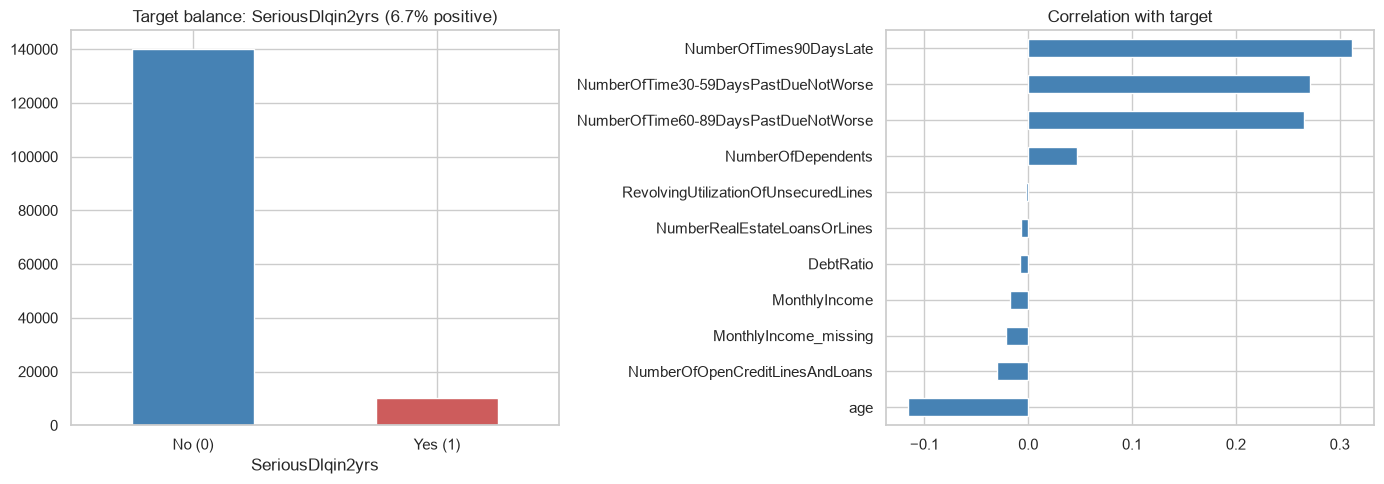

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

y.value_counts().plot(kind="bar", ax=axes[0], color=["steelblue", "indianred"])
axes[0].set_title(f"Target balance: SeriousDlqin2yrs ({y.mean():.1%} positive)")
axes[0].set_xticklabels(["No (0)", "Yes (1)"], rotation=0)

corr = df[feature_cols + ["SeriousDlqin2yrs"]].corr(numeric_only=True)["SeriousDlqin2yrs"].drop("SeriousDlqin2yrs")
corr.sort_values().plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Correlation with target")

plt.tight_layout()
plt.show()


With ~6.7% positive, a model that predicts "no delinquency" for everyone
scores 93.3% accuracy while being completely useless — the reason this notebook
leads with ROC-AUC rather than accuracy. The late-payment-count features
correlate most strongly with the target, which matches financial intuition: past
delinquency is the best predictor of future delinquency.


## 3. Train / test split

`stratify=y` keeps the ~6.7% positive rate consistent across train and test —
without it, an unlucky random split could meaningfully shift the minority class's
representation given how few positive examples there are. `StratifiedKFold`
plays the same role for every cross-validation step below, the classification
analogue of `TimeSeriesSplit` preserving time order in the previous notebook.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

skf = StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_STATE)
skf3 = StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape} ({y_train.mean():.2%} positive)")
print(f"Test:  {X_test.shape} ({y_test.mean():.2%} positive)")


Train: (119999, 11) (6.68% positive)
Test:  (30000, 11) (6.68% positive)


In [6]:
results = {}  # model_name -> metrics dict

def evaluate(name, y_true, y_pred_proba, threshold=0.5):
    y_pred = (y_pred_proba >= threshold).astype(int)
    metrics = {
        "ROC_AUC": roc_auc_score(y_true, y_pred_proba),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "LogLoss": log_loss(y_true, y_pred_proba),
    }
    results[name] = metrics
    print(f"{name:20s}  ROC_AUC={metrics['ROC_AUC']:.4f}  F1={metrics['F1']:.4f}  "
          f"Precision={metrics['Precision']:.4f}  Recall={metrics['Recall']:.4f}")
    return metrics


## 4. Logistic Regression

The classification baseline — models `log(p / (1-p))` as a linear function of the
features, rather than the outcome itself. Unregularized (`penalty=None`), as the
direct analogue of plain `LinearRegression`.


In [7]:
log_reg = LogisticRegression(C=np.inf, max_iter=2000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)

y_proba_lr = log_reg.predict_proba(X_test_scaled)[:, 1]
evaluate("LogisticRegression", y_test, y_proba_lr)


LogisticRegression    ROC_AUC=0.8145  F1=0.2371  Precision=0.5855  Recall=0.1486


{'ROC_AUC': 0.8144810860863558,
 'Accuracy': 0.9360666666666667,
 'Precision': 0.5854616895874263,
 'Recall': 0.1486284289276808,
 'F1': 0.23707239459029436,
 'LogLoss': 0.20015314340915583}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98115/3455420059.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")


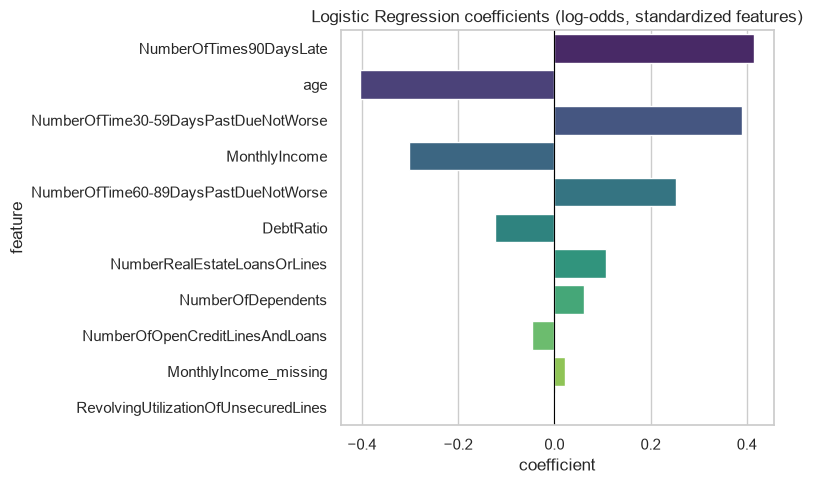

,feature,coefficient
6,NumberOfTimes90DaysLate,0.415510
1,age,-0.403497
2,NumberOfTime30-59DaysPastDueNotWorse,0.389239
4,MonthlyIncome,-0.301989
8,NumberOfTime60-89DaysPastDueNotWorse,0.252786
3,DebtRatio,-0.122390
7,NumberRealEstateLoansOrLines,0.107069
9,NumberOfDependents,0.061867
5,NumberOfOpenCreditLinesAndLoans,-0.046234
10,MonthlyIncome_missing,0.022717


In [8]:
coef_df = pd.DataFrame({
    "feature": feature_cols,
    "coefficient": log_reg.coef_[0]
}).sort_values("coefficient", key=abs, ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")
plt.title("Logistic Regression coefficients (log-odds, standardized features)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

coef_df


Coefficients are in **log-odds** units now, not the raw target's units —
a one-standard-deviation increase in a feature with coefficient `β` multiplies the
odds of delinquency by `exp(β)`. The late-payment-count features dominate, as the
correlation plot predicted.


## 5. Regularized Logistic Regression: L2, L1 & Elastic Net

scikit-learn has no `RidgeClassifierCV`-style class that mirrors `RidgeCV` for
logistic regression; `LogisticRegressionCV` covers all three penalties directly,
cross-validating the inverse regularization strength `C` (note: `C` is the
*inverse* of `alpha` — smaller `C` means *more* regularization, the opposite
direction from Ridge/Lasso's `alpha`).


In [9]:
Cs = np.logspace(-2, 2, 3)

l2_logreg = LogisticRegressionCV(
    Cs=Cs, l1_ratios=[0.0], use_legacy_attributes=False, solver="lbfgs", cv=skf, scoring="roc_auc",
    max_iter=2000, random_state=RANDOM_STATE, n_jobs=2, tol=1e-2,
)
l2_logreg.fit(X_train_scaled, y_train)

y_proba_l2 = l2_logreg.predict_proba(X_test_scaled)[:, 1]
evaluate("LogReg (L2)", y_test, y_proba_l2)
print(f"Chosen C: {l2_logreg.C_:.4f}")


LogReg (L2)           ROC_AUC=0.8168  F1=0.2087  Precision=0.5921  Recall=0.1267
Chosen C: 0.0100


In [10]:
l1_logreg = LogisticRegressionCV(
    Cs=Cs, l1_ratios=[1.0], use_legacy_attributes=False, solver="saga", cv=skf, scoring="roc_auc",
    max_iter=2000, random_state=RANDOM_STATE, n_jobs=2, tol=1e-2,
)
l1_logreg.fit(X_train_scaled, y_train)

y_proba_l1 = l1_logreg.predict_proba(X_test_scaled)[:, 1]
evaluate("LogReg (L1)", y_test, y_proba_l1)
print(f"Chosen C: {l1_logreg.C_:.4f}")
print(f"Features zeroed out: {(l1_logreg.coef_[0] == 0).sum()} / {len(feature_cols)}")


LogReg (L1)           ROC_AUC=0.8164  F1=0.2292  Precision=0.5825  Recall=0.1426
Chosen C: 0.0100
Features zeroed out: 2 / 11


In [11]:
elastic_logreg = LogisticRegressionCV(
    Cs=Cs, use_legacy_attributes=False, solver="saga", l1_ratios=[.5],
    cv=skf, scoring="roc_auc", max_iter=2000, random_state=RANDOM_STATE, n_jobs=2, tol=1e-2,
)
elastic_logreg.fit(X_train_scaled, y_train)

y_proba_elastic = elastic_logreg.predict_proba(X_test_scaled)[:, 1]
evaluate("LogReg (ElasticNet)", y_test, y_proba_elastic)
print(f"Chosen C: {elastic_logreg.C_:.4f}, l1_ratio: {elastic_logreg.l1_ratio_:.2f}")


LogReg (ElasticNet)   ROC_AUC=0.8158  F1=0.2310  Precision=0.5815  Recall=0.1441
Chosen C: 0.0100, l1_ratio: 0.50


On a dataset this clean (10 features, only one genuinely redundant pair —
the three late-payment-count columns correlate with each other), regularization
has little room to improve on plain logistic regression. Its value here is mostly
reassurance: confirming the unregularized model wasn't already overfitting.


## 6. K-Nearest Neighbors (KNN)

A genuinely different kind of model from everything else in this notebook: KNN
has no coefficients and builds no trees. It predicts a point's class
probability from the (optionally distance-weighted) vote of its `k` nearest
training points in feature space — "nearest" measured on the *scaled* features
(the same `X_train_scaled`/`X_test_scaled` used by the logistic regression
variants and MLP above), since distance is meaningless once features sit on
wildly different raw scales.

**When to reach for it:** a quick, assumption-light baseline — no linearity, no
tree-splittable structure, nothing learned at "training" time (there's no
training at all; `.fit()` just stores the data).

**Key hyperparameters:**
- `n_neighbors` (k): more neighbors → smoother, more biased predictions; fewer →
  noisier, more variance.
- `weights`: `"uniform"` averages neighbors equally; `"distance"` weights closer
  neighbors more heavily.
- `p`: the distance metric's power — `1` = Manhattan, `2` = Euclidean.

**Limitations:** prediction is slow on large datasets (every query compares
against the full training set); accuracy degrades in high dimensions (the
"curse of dimensionality" — with enough dimensions, every point ends up roughly
equidistant from every other).


In [12]:
knn = KNeighborsClassifier(n_neighbors=15, weights="distance")
knn.fit(X_train_scaled, y_train)

y_proba_knn = knn.predict_proba(X_test_scaled)[:, 1]
evaluate("KNN", y_test, y_proba_knn)


KNN                   ROC_AUC=0.7790  F1=0.2640  Precision=0.4700  Recall=0.1835


{'ROC_AUC': 0.7789980220016133,
 'Accuracy': 0.9316,
 'Precision': 0.46998722860791825,
 'Recall': 0.18354114713216957,
 'F1': 0.26398852223816355,
 'LogLoss': 0.639195029472109}

### Hyperparameter tuning with `GridSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [13]:
knn_param_grid = {'n_neighbors': [5, 15], 'weights': ['distance'], 'p': [2]}


knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid=knn_param_grid,
    cv=skf3,
    scoring="roc_auc",
    n_jobs=2,
)
knn_grid.fit(X_train_scaled, y_train)

print(f"Best params: {knn_grid.best_params_}")
print(f"Best CV ROC-AUC: {knn_grid.best_score_:.4f}")


Best params: {'n_neighbors': 15, 'p': 2, 'weights': 'distance'}
Best CV ROC-AUC: 0.7734


In [14]:
y_proba_knn_tuned = knn_grid.best_estimator_.predict_proba(X_test_scaled)[:, 1]
evaluate("KNN (tuned)", y_test, y_proba_knn_tuned)


KNN (tuned)           ROC_AUC=0.7790  F1=0.2640  Precision=0.4700  Recall=0.1835


{'ROC_AUC': 0.7789980220016133,
 'Accuracy': 0.9316,
 'Precision': 0.46998722860791825,
 'Recall': 0.18354114713216957,
 'F1': 0.26398852223816355,
 'LogLoss': 0.639195029472109}

## 7. MLP (Multi-Layer Perceptron)


In [15]:
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    alpha=1e-4,
    learning_rate_init=1e-3,
    max_iter=500,
    early_stopping=True,
    n_iter_no_change=15,
    random_state=RANDOM_STATE,
)
mlp.fit(X_train_scaled, y_train)

y_proba_mlp = mlp.predict_proba(X_test_scaled)[:, 1]
evaluate("MLP", y_test, y_proba_mlp)


MLP                   ROC_AUC=0.8353  F1=0.2717  Precision=0.5537  Recall=0.1800


{'ROC_AUC': 0.8353242986479149,
 'Accuracy': 0.9355,
 'Precision': 0.553680981595092,
 'Recall': 0.1800498753117207,
 'F1': 0.2717350395182537,
 'LogLoss': 0.18876437408072258}

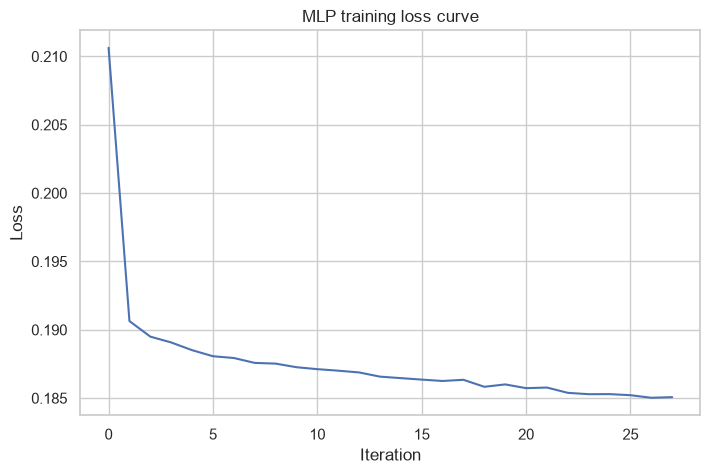

In [16]:
plt.plot(mlp.loss_curve_)
plt.title("MLP training loss curve")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [17]:
mlp_param_dist = {'hidden_layer_sizes': [(64, 32)], 'alpha': [0.0001, 0.001]}


mlp_search = RandomizedSearchCV(
    MLPClassifier(
        activation="relu", learning_rate_init=1e-3, max_iter=500,
        early_stopping=True, n_iter_no_change=15, random_state=RANDOM_STATE,
    ),
    param_distributions=mlp_param_dist,
    n_iter=2, cv=skf3, scoring="roc_auc", n_jobs=2, random_state=RANDOM_STATE,
)
mlp_search.fit(X_train_scaled, y_train)

print(f"Best params: {mlp_search.best_params_}")
print(f"Best CV ROC-AUC: {mlp_search.best_score_:.4f}")


Best params: {'hidden_layer_sizes': (64, 32), 'alpha': 0.001}
Best CV ROC-AUC: 0.8293


In [18]:
y_proba_mlp_tuned = mlp_search.best_estimator_.predict_proba(X_test_scaled)[:, 1]
evaluate("MLP (tuned)", y_test, y_proba_mlp_tuned)


MLP (tuned)           ROC_AUC=0.8338  F1=0.2943  Precision=0.5250  Recall=0.2045


{'ROC_AUC': 0.8337623168369486,
 'Accuracy': 0.9344666666666667,
 'Precision': 0.5249679897567221,
 'Recall': 0.20448877805486285,
 'F1': 0.29432878679109836,
 'LogLoss': 0.18933674983812646}

## 8. Random Forest


In [19]:
rf = RandomForestClassifier(
    n_estimators=300, max_depth=None, min_samples_leaf=2,
    n_jobs=2, random_state=RANDOM_STATE,
)
rf.fit(X_train, y_train)

y_proba_rf = rf.predict_proba(X_test)[:, 1]
evaluate("RandomForest", y_test, y_proba_rf)


RandomForest          ROC_AUC=0.8558  F1=0.2705  Precision=0.5678  Recall=0.1776


{'ROC_AUC': 0.8558033207746841,
 'Accuracy': 0.936,
 'Precision': 0.5677830940988836,
 'Recall': 0.17755610972568578,
 'F1': 0.270516717325228,
 'LogLoss': 0.1898006413742805}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98115/4022785580.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")


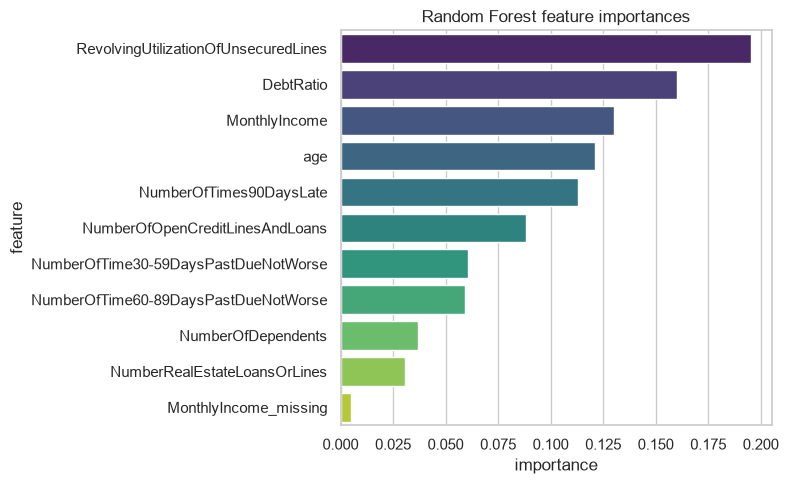

,feature,importance
0,RevolvingUtilizationOfUnsecuredLines,0.195430
3,DebtRatio,0.160111
4,MonthlyIncome,0.130366
1,age,0.121057
6,NumberOfTimes90DaysLate,0.112884
5,NumberOfOpenCreditLinesAndLoans,0.088144
2,NumberOfTime30-59DaysPastDueNotWorse,0.060465
8,NumberOfTime60-89DaysPastDueNotWorse,0.058997
9,NumberOfDependents,0.037068
7,NumberRealEstateLoansOrLines,0.030570


In [20]:
rf_importance = pd.DataFrame({
    "feature": feature_cols, "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")
plt.title("Random Forest feature importances")
plt.tight_layout()
plt.show()
rf_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [21]:
rf_param_dist = {'n_estimators': [300], 'max_depth': [8, 12], 'min_samples_leaf': [2, 5]}


rf_search = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=2, random_state=RANDOM_STATE),
    param_distributions=rf_param_dist,
    n_iter=2, cv=skf3, scoring="roc_auc", n_jobs=2, random_state=RANDOM_STATE,
)
rf_search.fit(X_train, y_train)

print(f"Best params: {rf_search.best_params_}")
print(f"Best CV ROC-AUC: {rf_search.best_score_:.4f}")


Best params: {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}
Best CV ROC-AUC: 0.8623


In [22]:
y_proba_rf_tuned = rf_search.best_estimator_.predict_proba(X_test)[:, 1]
evaluate("RandomForest (tuned)", y_test, y_proba_rf_tuned)


RandomForest (tuned)  ROC_AUC=0.8683  F1=0.2513  Precision=0.5836  Recall=0.1601


{'ROC_AUC': 0.8682972066173199,
 'Accuracy': 0.9362333333333334,
 'Precision': 0.5836363636363636,
 'Recall': 0.1600997506234414,
 'F1': 0.2512720156555773,
 'LogLoss': 0.1774147424463194}

## 9. XGBoost (Extreme Gradient Boosting)


In [23]:
xgb = XGBClassifier(
    n_estimators=500, learning_rate=0.05, max_depth=5,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
    eval_metric="auc", random_state=RANDOM_STATE, n_jobs=2,
)
xgb.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

y_proba_xgb = xgb.predict_proba(X_test)[:, 1]
evaluate("XGBoost", y_test, y_proba_xgb)


XGBoost               ROC_AUC=0.8665  F1=0.2864  Precision=0.5629  Recall=0.1920


{'ROC_AUC': 0.866489233248367,
 'Accuracy': 0.9360333333333334,
 'Precision': 0.5628654970760234,
 'Recall': 0.19201995012468828,
 'F1': 0.2863518036444775,
 'LogLoss': 0.17805200815200806}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98115/3462201617.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")


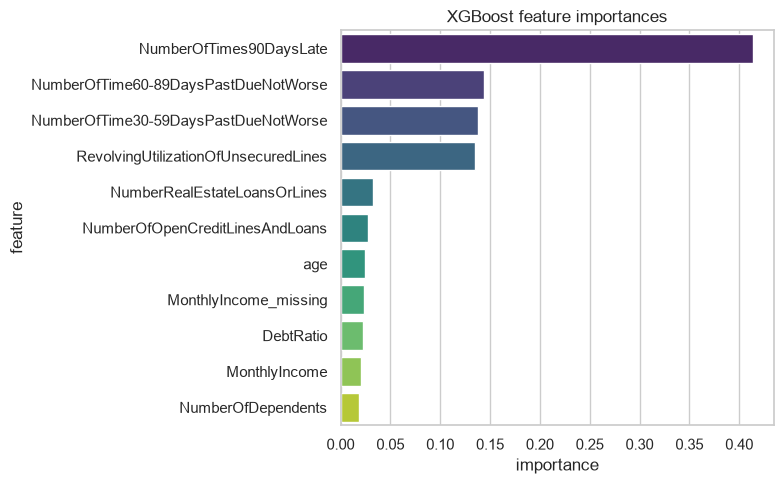

,feature,importance
6,NumberOfTimes90DaysLate,0.414182
8,NumberOfTime60-89DaysPastDueNotWorse,0.143630
2,NumberOfTime30-59DaysPastDueNotWorse,0.138244
0,RevolvingUtilizationOfUnsecuredLines,0.134963
7,NumberRealEstateLoansOrLines,0.032116
5,NumberOfOpenCreditLinesAndLoans,0.027804
1,age,0.024695
10,MonthlyIncome_missing,0.023346
3,DebtRatio,0.022260
4,MonthlyIncome,0.020744


In [24]:
xgb_importance = pd.DataFrame({
    "feature": feature_cols, "importance": xgb.feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")
plt.title("XGBoost feature importances")
plt.tight_layout()
plt.show()
xgb_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [25]:
xgb_param_dist = {'n_estimators': [500], 'max_depth': [3, 5], 'learning_rate': [0.03, 0.05]}


xgb_search = RandomizedSearchCV(
    XGBClassifier(subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                  eval_metric="auc", random_state=RANDOM_STATE, n_jobs=2),
    param_distributions=xgb_param_dist,
    n_iter=2, cv=skf3, scoring="roc_auc", n_jobs=2, random_state=RANDOM_STATE,
)
xgb_search.fit(X_train, y_train)

print(f"Best params: {xgb_search.best_params_}")
print(f"Best CV ROC-AUC: {xgb_search.best_score_:.4f}")


Best params: {'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.03}
Best CV ROC-AUC: 0.8620


In [26]:
y_proba_xgb_tuned = xgb_search.best_estimator_.predict_proba(X_test)[:, 1]
evaluate("XGBoost (tuned)", y_test, y_proba_xgb_tuned)


XGBoost (tuned)       ROC_AUC=0.8690  F1=0.2846  Precision=0.5806  Recall=0.1885


{'ROC_AUC': 0.8689674545552531,
 'Accuracy': 0.9366666666666666,
 'Precision': 0.5806451612903226,
 'Recall': 0.1885286783042394,
 'F1': 0.28463855421686746,
 'LogLoss': 0.17679260671138763}

## 10. CatBoost (Categorical Boosting)

All-numeric dataset here (no categorical columns), so this is plain
`CatBoostClassifier` with no `cat_features` to pass — included for completeness
and consistency with the rest of the series.


In [27]:
cat = CatBoostClassifier(iterations=500, learning_rate=0.05, depth=6, l2_leaf_reg=3.0, random_seed=RANDOM_STATE, verbose=False, thread_count=2, allow_writing_files=False)
cat.fit(X_train, y_train, eval_set=(X_test, y_test), use_best_model=True)

y_proba_cat = cat.predict_proba(X_test)[:, 1]
evaluate("CatBoost", y_test, y_proba_cat)


CatBoost              ROC_AUC=0.8695  F1=0.2777  Precision=0.5752  Recall=0.1830


{'ROC_AUC': 0.8695257124201463,
 'Accuracy': 0.9363666666666667,
 'Precision': 0.5752351097178683,
 'Recall': 0.18304239401496258,
 'F1': 0.2777147181233447,
 'LogLoss': 0.17654621402754475}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98115/1213037597.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")


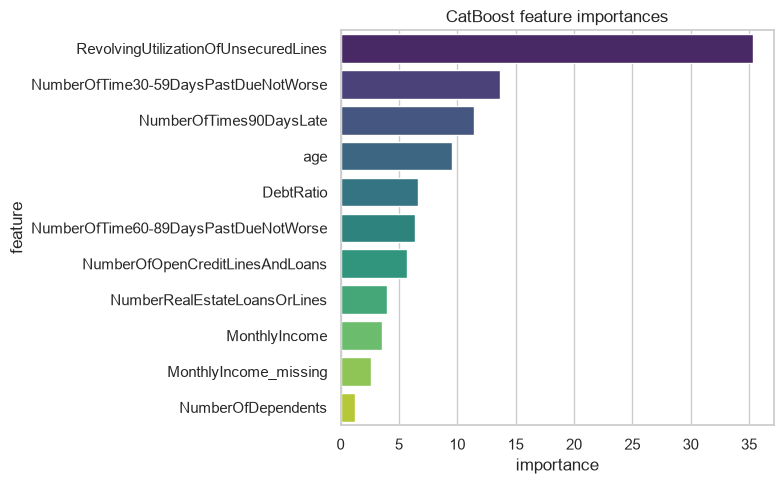

,feature,importance
0,RevolvingUtilizationOfUnsecuredLines,35.367648
2,NumberOfTime30-59DaysPastDueNotWorse,13.694669
6,NumberOfTimes90DaysLate,11.405790
1,age,9.539542
3,DebtRatio,6.598070
8,NumberOfTime60-89DaysPastDueNotWorse,6.415652
5,NumberOfOpenCreditLinesAndLoans,5.682974
7,NumberRealEstateLoansOrLines,3.957244
4,MonthlyIncome,3.510312
10,MonthlyIncome_missing,2.608370


In [28]:
cat_importance = pd.DataFrame({
    "feature": feature_cols, "importance": cat.get_feature_importance()
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")
plt.title("CatBoost feature importances")
plt.tight_layout()
plt.show()
cat_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [29]:
cat_param_dist = {'iterations': [500], 'depth': [4, 6], 'learning_rate': [0.03, 0.05]}


cat_search = RandomizedSearchCV(
    CatBoostClassifier(l2_leaf_reg=3.0, random_seed=RANDOM_STATE, thread_count=1, allow_writing_files=False, verbose=False),
    param_distributions=cat_param_dist,
    n_iter=2, cv=skf3, scoring="roc_auc", n_jobs=2, random_state=RANDOM_STATE,
)
cat_search.fit(X_train, y_train)

print(f"Best params: {cat_search.best_params_}")
print(f"Best CV ROC-AUC: {cat_search.best_score_:.4f}")


Best params: {'learning_rate': 0.05, 'iterations': 500, 'depth': 6}
Best CV ROC-AUC: 0.8637


In [30]:
y_proba_cat_tuned = cat_search.best_estimator_.predict_proba(X_test)[:, 1]
evaluate("CatBoost (tuned)", y_test, y_proba_cat_tuned)


CatBoost (tuned)      ROC_AUC=0.8696  F1=0.2841  Precision=0.5762  Recall=0.1885


{'ROC_AUC': 0.8696363663087325,
 'Accuracy': 0.9365,
 'Precision': 0.5762195121951219,
 'Recall': 0.1885286783042394,
 'F1': 0.28410372040586246,
 'LogLoss': 0.1766425262758299}

## 11. LightGBM (Light Gradient Boosting Machine)


In [31]:
lgbm = LGBMClassifier(
    n_estimators=500, learning_rate=0.05, num_leaves=31, min_child_samples=20,
    subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=2, verbose=-1,
)
lgbm.fit(X_train, y_train, eval_set=[(X_test, y_test)])

y_proba_lgbm = lgbm.predict_proba(X_test)[:, 1]
evaluate("LightGBM", y_test, y_proba_lgbm)


LightGBM              ROC_AUC=0.8662  F1=0.2813  Precision=0.5629  Recall=0.1875


{'ROC_AUC': 0.8662377455183261,
 'Accuracy': 0.9359666666666666,
 'Precision': 0.562874251497006,
 'Recall': 0.18753117206982545,
 'F1': 0.28133183688739244,
 'LogLoss': 0.1781006852679014}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98115/3896420235.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")


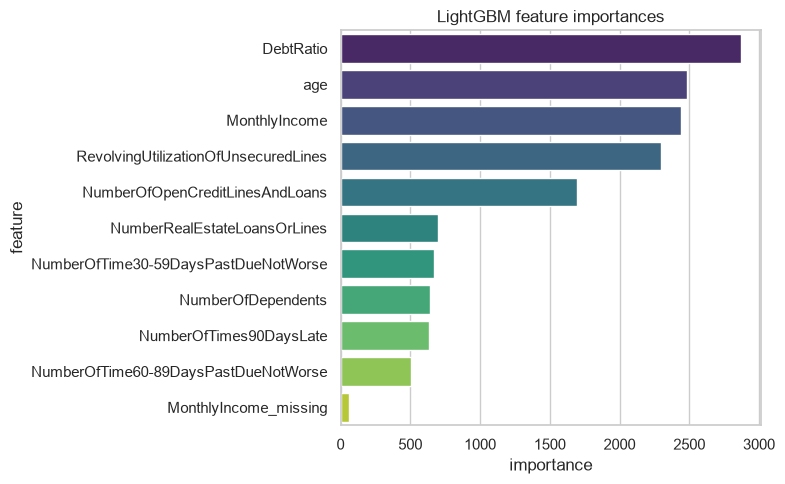

,feature,importance
3,DebtRatio,2872
1,age,2485
4,MonthlyIncome,2443
0,RevolvingUtilizationOfUnsecuredLines,2297
5,NumberOfOpenCreditLinesAndLoans,1695
7,NumberRealEstateLoansOrLines,699
2,NumberOfTime30-59DaysPastDueNotWorse,671
9,NumberOfDependents,642
6,NumberOfTimes90DaysLate,633
8,NumberOfTime60-89DaysPastDueNotWorse,502


In [32]:
lgbm_importance = pd.DataFrame({
    "feature": feature_cols, "importance": lgbm.feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")
plt.title("LightGBM feature importances")
plt.tight_layout()
plt.show()
lgbm_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [33]:
lgbm_param_dist = {'n_estimators': [500], 'num_leaves': [15, 31], 'learning_rate': [0.03, 0.05]}


lgbm_search = RandomizedSearchCV(
    LGBMClassifier(subsample=0.8, colsample_bytree=0.8, min_child_samples=20,
                   random_state=RANDOM_STATE, n_jobs=2, verbose=-1),
    param_distributions=lgbm_param_dist,
    n_iter=2, cv=skf3, scoring="roc_auc", n_jobs=2, random_state=RANDOM_STATE,
)
lgbm_search.fit(X_train, y_train)

print(f"Best params: {lgbm_search.best_params_}")
print(f"Best CV ROC-AUC: {lgbm_search.best_score_:.4f}")


Best params: {'num_leaves': 31, 'n_estimators': 500, 'learning_rate': 0.03}
Best CV ROC-AUC: 0.8597


In [34]:
y_proba_lgbm_tuned = lgbm_search.best_estimator_.predict_proba(X_test)[:, 1]
evaluate("LightGBM (tuned)", y_test, y_proba_lgbm_tuned)


LightGBM (tuned)      ROC_AUC=0.8682  F1=0.2841  Precision=0.5809  Recall=0.1880


{'ROC_AUC': 0.8681778764376789,
 'Accuracy': 0.9366666666666666,
 'Precision': 0.5808936825885979,
 'Recall': 0.18802992518703243,
 'F1': 0.28409947249434814,
 'LogLoss': 0.17700380871895993}

## 12. Head-to-head comparison

Higher is better for every metric here except `LogLoss` (lower is better).


In [35]:
results_df = pd.DataFrame(results).T.sort_values("ROC_AUC", ascending=False)
results_df


,ROC_AUC,Accuracy,Precision,Recall,F1,LogLoss
CatBoost (tuned),0.869636,0.936500,0.576220,0.188529,0.284104,0.176643
CatBoost,0.869526,0.936367,0.575235,0.183042,0.277715,0.176546
XGBoost (tuned),0.868967,0.936667,0.580645,0.188529,0.284639,0.176793
RandomForest (tuned),0.868297,0.936233,0.583636,0.160100,0.251272,0.177415
LightGBM (tuned),0.868178,0.936667,0.580894,0.188030,0.284099,0.177004
XGBoost,0.866489,0.936033,0.562865,0.192020,0.286352,0.178052
LightGBM,0.866238,0.935967,0.562874,0.187531,0.281332,0.178101
RandomForest,0.855803,0.936000,0.567783,0.177556,0.270517,0.189801
MLP,0.835324,0.935500,0.553681,0.180050,0.271735,0.188764
MLP (tuned),0.833762,0.934467,0.524968,0.204489,0.294329,0.189337


/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98115/1586291664.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, "ROC_AUC"], y=order, palette="viridis", ax=axes[0])


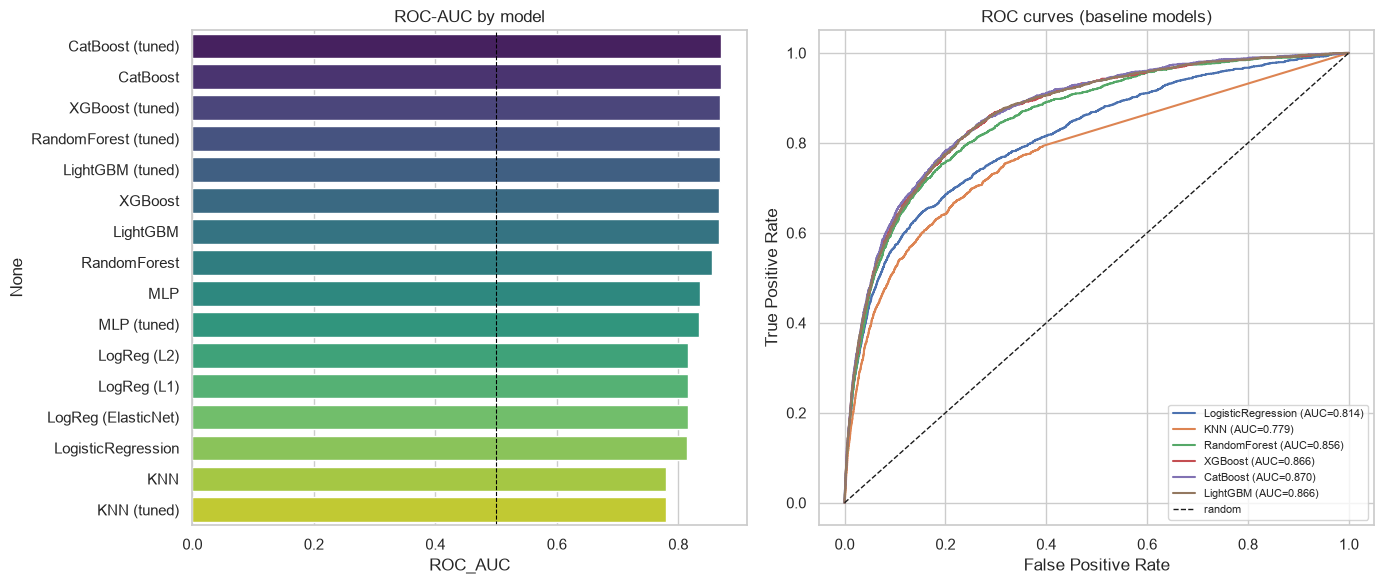

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

order = results_df.index
sns.barplot(x=results_df.loc[order, "ROC_AUC"], y=order, palette="viridis", ax=axes[0])
axes[0].set_title("ROC-AUC by model")
axes[0].axvline(0.5, color="black", linewidth=0.8, linestyle="--")

probas = {
    "LogisticRegression": y_proba_lr, "KNN": y_proba_knn, "RandomForest": y_proba_rf,
    "XGBoost": y_proba_xgb, "CatBoost": y_proba_cat, "LightGBM": y_proba_lgbm,
}
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1, label="random")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC curves (baseline models)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()


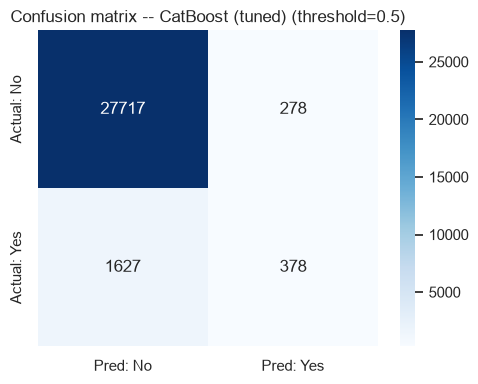

At the default 0.5 threshold, CatBoost (tuned) catches 378/2005 (18.9%) of actual delinquencies, at the cost of 278 false alarms out of 27995 non-delinquent applicants.


In [37]:
best_model_name = results_df.index[0]
best_proba = {**probas, "MLP": y_proba_mlp,
              "MLP (tuned)": y_proba_mlp_tuned, "RandomForest (tuned)": y_proba_rf_tuned,
              "XGBoost (tuned)": y_proba_xgb_tuned, "CatBoost (tuned)": y_proba_cat_tuned,
              "LightGBM (tuned)": y_proba_lgbm_tuned}[best_model_name]

cm = confusion_matrix(y_test, (best_proba >= 0.5).astype(int))
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred: No", "Pred: Yes"], yticklabels=["Actual: No", "Actual: Yes"])
plt.title(f"Confusion matrix -- {best_model_name} (threshold=0.5)")
plt.tight_layout()
plt.show()

print(f"At the default 0.5 threshold, {best_model_name} catches "
      f"{cm[1,1]}/{cm[1].sum()} ({cm[1,1]/cm[1].sum():.1%}) of actual delinquencies, "
      f"at the cost of {cm[0,1]} false alarms out of {cm[0].sum()} non-delinquent applicants.")


The confusion matrix at the default 0.5 threshold usually looks worse than
the ROC-AUC number suggests — with only ~6.7% positives, 0.5 is rarely the
business-optimal threshold. In a real credit-scoring deployment, the threshold
would be set by the actual cost of a missed default vs. a wrongly-declined good
applicant, not left at the default.


## 13. Stacking

Combine Random Forest, XGBoost and LightGBM with a linear meta-model. The meta-model learns from out-of-fold predictions within the training partition. Compare the resulting ensemble with the individual models on the held-out partition.

In [38]:
from sklearn.ensemble import StackingClassifier

stack = StackingClassifier(
    estimators=[("forest", rf), ("xgboost", xgb), ("lightgbm", lgbm)],
    final_estimator=LogisticRegression(C=1.0, max_iter=2000, random_state=RANDOM_STATE),
    cv=2,
    n_jobs=2,
)
stack.fit(X_train_scaled, y_train)
y_proba_stack = stack.predict_proba(X_test_scaled)[:, 1]
evaluate("Stacking", y_test, y_proba_stack)


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Stacking              ROC_AUC=0.8647  F1=0.2999  Precision=0.5584  Recall=0.2050


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


{'ROC_AUC': 0.8647012670146388,
 'Accuracy': 0.9360333333333334,
 'Precision': 0.5584239130434783,
 'Recall': 0.20498753117206983,
 'F1': 0.2998905508938344,
 'LogLoss': 0.18857205534705712}

## 14. Conclusion

Use the measured comparison to discuss accuracy, interpretability and training cost. Regularized linear models are useful references for correlated inputs. KNN depends on the distance representation. MLP needs scaling and optimization checks. Tree ensembles capture nonlinear interactions, and stacking adds a meta-model trained on out-of-fold predictions.

Report the best measured result together with its metric and validation design. Inspect errors within important target ranges or groups before choosing a model for a new population.

In [39]:
final_results = pd.DataFrame(results).T.sort_values('ROC_AUC', ascending=False)
print("Results from this run")
display(final_results)


Results from this run


,ROC_AUC,Accuracy,Precision,Recall,F1,LogLoss
CatBoost (tuned),0.869636,0.936500,0.576220,0.188529,0.284104,0.176643
CatBoost,0.869526,0.936367,0.575235,0.183042,0.277715,0.176546
XGBoost (tuned),0.868967,0.936667,0.580645,0.188529,0.284639,0.176793
RandomForest (tuned),0.868297,0.936233,0.583636,0.160100,0.251272,0.177415
LightGBM (tuned),0.868178,0.936667,0.580894,0.188030,0.284099,0.177004
XGBoost,0.866489,0.936033,0.562865,0.192020,0.286352,0.178052
LightGBM,0.866238,0.935967,0.562874,0.187531,0.281332,0.178101
Stacking,0.864701,0.936033,0.558424,0.204988,0.299891,0.188572
RandomForest,0.855803,0.936000,0.567783,0.177556,0.270517,0.189801
MLP,0.835324,0.935500,0.553681,0.180050,0.271735,0.188764
